# Over 0.5 FT (Lay 0 x 0)

### Importando as Bibliotecas

In [1]:
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings('ignore')

def drop_reset_index(df):
    df = df.dropna()
    df = df.reset_index(drop=True)
    df.index += 1
    return df

def plot_profit_acu(dataframe, title_text):
    dataframe['Profit_acu'] = dataframe.Profit.cumsum()
    n_apostas = dataframe.shape[0]
    profit = round(dataframe.Profit_acu.tail(1).item(), 2)
    dataframe['Investimento_acu'] = dataframe.Investimento.cumsum()
    ROI = round(((dataframe.Profit_acu.tail(1) / dataframe.Investimento_acu.tail(1)) * 100).item(), 2)
    drawdown = dataframe['Profit_acu'] - dataframe['Profit_acu'].cummax()
    drawdown_maximo = round(drawdown.min(), 2)
    winrate_medio = round((dataframe['Profit'] > 0).mean() * 100, 2)
    desvio_padrao = round(dataframe['Profit'].std(), 2)
    dataframe.Profit_acu.plot(title=title_text, xlabel='Entradas', ylabel='Stakes')
    print("Metodo:",title_text)
    print("Profit:", profit, "stakes em", n_apostas, "jogos")
    print("ROI:", ROI, "%")
    print("Drawdown Maximo Acumulado:", drawdown_maximo)
    print("Winrate Medio:", winrate_medio, "%")
    print("Desvio Padrao:", desvio_padrao)
    print("")

=== Results without filters 👇 ===
Total number of games: 643
Return betting Home Team: -13.08 units ❌

 === Results with filters 👇 === 

Total number of games: 143
Return betting Home Team: 16.31 units ✅
Average Odd: 2.58
Max consecutive losses: 8
Max Drawdown: -10.82 units
Max consecutive wins: 5
Win rate: 44.76%
ROI: 11.41%


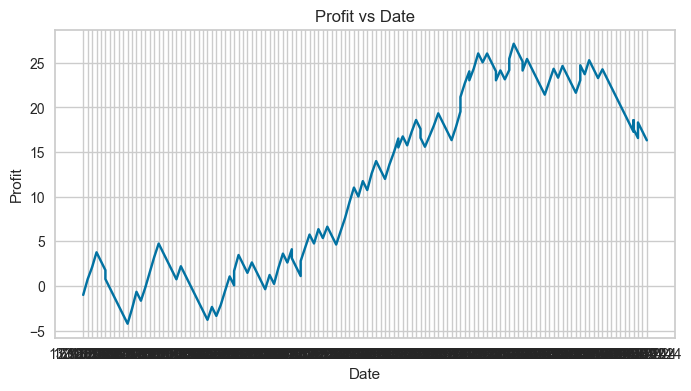

In [ ]:
print('=== Results without filters 👇 ===')
print('Total number of games:', test_dataset.shape[0])

if test_dataset['Bet_Home_Profit'].sum() > 0:
    print(f"Return betting Home Team: {round(test_dataset['Bet_Home_Profit'].sum()/stake, 2)} units ✅")
else:
    print(f"Return betting Home Team: {round(test_dataset['Bet_Home_Profit'].sum()/stake, 2)} units ❌")    

# STRATEGY
strat = test_dataset[(test_dataset.Away_Draw < 1) & (test_dataset.PSH < 3)]

print('\n === Results with filters 👇 === \n')
print(f'Total number of games: {strat.shape[0]}')

if strat['Bet_Home_Profit'].sum() > 0:
    print(f'Return betting Home Team: {round(strat["Bet_Home_Profit"].sum()/stake, 2)} units ✅')
else:
    print(f'Return betting Home Team: {round(strat["Bet_Home_Profit"].sum()/stake, 2)} units ❌')


print(f'Average Odd: {round(strat["PSH"].fillna(strat["PSCH"]).mean(), 2)}')

# calculate the max consecutive losses betting home
# correct this to if x == 'H' or 'D'
strat['Is_Loss'] = strat['FTR'].apply(lambda x: 1 if x in ['A', 'D'] else 0)
strat['Consecutive_Losses'] = (strat['Is_Loss'] * 
                               strat.groupby(strat['Is_Loss'].ne(strat['Is_Loss'].shift()).cumsum()).cumcount() + 1)

max_consecutive_losses = strat['Consecutive_Losses'].max()
print(f"Max consecutive losses: {max_consecutive_losses}")

strat['Profit_Cum'] = strat['Bet_Home_Profit'].cumsum()

#calculate the biggest negative trend in the Profit_Cum column
strat['Max_Profit'] = strat['Profit_Cum'].cummax()
strat['Drawdown'] = strat['Profit_Cum'] - strat['Max_Profit']

max_drawdown = strat['Drawdown'].min()
print(f"Max Drawdown: {round(max_drawdown/stake, 2)} units")

# calculate the max consecutive wins betting home
strat['Is_Win'] = strat['FTR'].apply(lambda x: 1 if x == 'H' else 0)
strat['Consecutive_Wins'] = (strat['Is_Win'] * 
                             strat.groupby(strat['Is_Win'].ne(strat['Is_Win'].shift()).cumsum()).cumcount() + 1)

max_consecutive_wins = strat['Consecutive_Wins'].max()
print(f"Max consecutive wins: {max_consecutive_wins}")

# calculate the win rate
win_rate = strat[strat['FTR'] == 'H'].shape[0]/strat.shape[0]*100
print(f"Win rate: {round(win_rate, 2)}%")

# calculate the ROI of betting home team
roi =  (strat['Bet_Home_Profit'].sum()/(strat.shape[0]*stake)) * 100

print(f"ROI: {round(roi, 2)}%")

#draw a graph of the Profit_Cum vs the Date
plt.figure(figsize=(8, 4))
plt.plot(strat['Date'], strat['Profit_Cum'])
plt.xlabel('Date')
plt.ylabel('Profit')
plt.title('Profit vs Date')
plt.show()

In [2]:
def rename_leagues(df):
    df.replace('Argentinian Copa de la Liga Profesional','ARGENTINA - COPA DE LA LIGA PROFESIONAL', inplace=True)
    df.replace('Argentinian Primera Division','ARGENTINA - LIGA PROFESIONAL', inplace=True)
    df.replace('Armenian Premier League','ARMENIA - PREMIER LEAGUE', inplace=True)
    df.replace('Australian A-League Men','AUSTRALIA - A-LEAGUE', inplace=True)
    df.replace('Austrian Bundesliga','AUSTRIA - 2. LIGA', inplace=True)
    df.replace('Austrian Erste Liga','AUSTRIA - BUNDESLIGA', inplace=True)
    df.replace('Belgian First Division B','BELGIUM - CHALLENGER PRO LEAGUE', inplace=True)
    df.replace('Belgian First Division A','BELGIUM - JUPILER PRO LEAGUE', inplace=True)
    df.replace('Bolivian Liga de Futbol Profesional','BOLIVIA - DIVISION PROFESIONAL', inplace=True)
    df.replace('Bosnian Premier League','BOSNIA AND HERZEGOVINA - PREMIJER LIGA BIH', inplace=True)
    df.replace('Brazilian Serie A','BRAZIL - SERIE A', inplace=True)
    df.replace('Brazilian Serie B','BRAZIL - SERIE B', inplace=True)
    df.replace('Brazilian Serie C','BRAZIL - SERIE C', inplace=True)
    df.replace('Brazilian Serie D','BRAZIL - SERIE D', inplace=True)
    df.replace('Bulgarian A League','BULGARIA - PARVA LIGA', inplace=True)
    df.replace('Chilean Primera Division','CHILE - PRIMERA DIVISION', inplace=True)
    df.replace('Chinese Super League','CHINA - SUPER LEAGUE', inplace=True)
    df.replace('Colombian Primera A','COLOMBIA - PRIMERA A', inplace=True)
    df.replace('Croatian 1 HNL','CROATIA - HNL', inplace=True)
    df.replace('Croatian 2 HNL','CROATIA - PRVA NL', inplace=True)
    df.replace('Cypriot 1st Division','CYPRUS - CYTA CHAMPIONSHIP', inplace=True)
    df.replace('Czech 1 Liga','CZECH REPUBLIC - FORTUNA LIGA', inplace=True)
    df.replace('Danish 1st Division','DENMARK - 1ST DIVISION', inplace=True)
    df.replace('Danish Superliga','DENMARK - SUPERLIGA', inplace=True)
    df.replace('Ecuadorian Serie A','ECUADOR - LIGA PRO', inplace=True)
    df.replace('Egyptian Premier','EGYPT - PREMIER LEAGUE', inplace=True)
    df.replace('English Championship','ENGLAND - CHAMPIONSHIP', inplace=True)
    df.replace('English League 1','ENGLAND - LEAGUE ONE', inplace=True)
    df.replace('English League 2','ENGLAND - LEAGUE TWO', inplace=True)
    df.replace('English National League','ENGLAND - NATIONAL LEAGUE', inplace=True)
    df.replace('English Premier League','ENGLAND - PREMIER LEAGUE', inplace=True)
    df.replace('Estonian Esiliiga','ESTONIA - ESILIIGA', inplace=True)
    df.replace('Estonian Premier League','ESTONIA - MEISTRILIIGA', inplace=True)
    df.replace('UEFA Champions League','EUROPE - CHAMPIONS LEAGUE', inplace=True)
    df.replace('UEFA Europa Conference League','EUROPE - EUROPA CONFERENCE LEAG', inplace=True)
    df.replace('UEFA Europa League','EUROPE - EUROPA LEAGUE', inplace=True)
    df.replace('Finnish Veikkausliiga','FINLAND - VEIKKAUSLIIGA', inplace=True)
    df.replace('Finnish Ykkonen','FINLAND - YKKONEN', inplace=True)
    df.replace('French Ligue 1','FRANCE - LIGUE 1', inplace=True)
    df.replace('French Ligue 2','FRANCE - LIGUE 2', inplace=True)
    df.replace('French National','FRANCE - NATIONAL', inplace=True)
    df.replace('German Bundesliga 2','GERMANY - 2. BUNDESLIGA', inplace=True)
    df.replace('German 3 Liga','GERMANY - 3. LIGA', inplace=True)
    df.replace('German Bundesliga','GERMANY - BUNDESLIGA', inplace=True)
    df.replace('Greek Super League','GREECE - SUPER LEAGUE', inplace=True)
    df.replace('Hungarian NB I','HUNGARY - OTP BANK LIGA', inplace=True)
    #df.replace('????','ICELAND - BESTA DEILD KARLA', inplace=True)
    df.replace('Icelandic 1 Deild','ICELAND - LENGJUDEILDIN', inplace=True)
    df.replace('Irish Division 1','IRELAND - DIVISION 1', inplace=True)
    df.replace('Irish Premier Division','IRELAND - PREMIER DIVISION', inplace=True)
    df.replace('Israeli Premier League',"ISRAEL - LIGAT HA'AL", inplace=True)
    df.replace('Italian Serie A','ITALY - SERIE A', inplace=True)
    df.replace('Italian Serie B','ITALY - SERIE B', inplace=True)
    df.replace('Italian Serie C','ITALY - SERIE C', inplace=True)
    df.replace('Italian Serie D','ITALY - SERIE D', inplace=True)
    df.replace('Japanese J League','JAPAN - J1 LEAGUE', inplace=True)
    df.replace('Japanese J League 2','JAPAN - J2 LEAGUE', inplace=True)
    df.replace('Mexican Liga MX','MEXICO - LIGA MX', inplace=True)
    df.replace('Dutch Eerste Divisie','NETHERLANDS - EERSTE DIVISIE', inplace=True)
    df.replace('Dutch Eredivisie','NETHERLANDS - EREDIVISIE', inplace=True)
    df.replace('Northern Irish Championship','NORTHERN IRELAND - NIFL CHAMPIO', inplace=True)
    df.replace('Northern Irish Premiership','NORTHERN IRELAND - NIFL PREMIER', inplace=True)
    df.replace('Norwegian Eliteserien','NORWAY - ELITESERIEN', inplace=True)
    df.replace('Norwegian 1st Division','NORWAY - OBOS-LIGAEN', inplace=True)
    df.replace('Paraguayan Primera Division','PARAGUAY - PRIMERA DIVISION', inplace=True)
    df.replace('Peruvian Primera Division','PERU - LIGA 1', inplace=True)
    df.replace('Polish I Liga','POLAND - DIVISION 1', inplace=True)
    df.replace('Polish Ekstraklasa','POLAND - EKSTRAKLASA', inplace=True)
    df.replace('Portuguese Primeira Liga','PORTUGAL - LIGA PORTUGAL', inplace=True)
    df.replace('Portuguese Segunda Liga','PORTUGAL - LIGA PORTUGAL 2', inplace=True)
    df.replace('Romanian Liga I','ROMANIA - LIGA 1', inplace=True)
    df.replace('Romanian Liga II','ROMANIA - LIGA 2', inplace=True)
    df.replace('Saudi Professional League','SAUDI ARABIA - SAUDI PROFESSION', inplace=True)
    df.replace('Scottish Championship','SCOTLAND - CHAMPIONSHIP', inplace=True)
    df.replace('Scottish League One','SCOTLAND - LEAGUE ONE', inplace=True)
    df.replace('Scottish League Two','SCOTLAND - LEAGUE TWO', inplace=True)
    df.replace('Scottish Premiership','SCOTLAND - PREMIERSHIP', inplace=True)
    df.replace('Serbian First League','SERBIA - PRVA LIGA', inplace=True)
    df.replace('Serbian Super League','SERBIA - SUPER LIGA', inplace=True)
    df.replace('Slovakian Super League','SLOVAKIA - NIKE LIGA', inplace=True)
    df.replace('Slovenian Premier League','SLOVENIA - PRVA LIGA', inplace=True)
    df.replace('South African Premier Division','SOUTH AFRICA - PREMIER LEAGUE', inplace=True)
    df.replace('CONMEBOL Copa Libertadores','SOUTH AMERICA - COPA LIBERTADOR', inplace=True)
    df.replace('CONMEBOL Copa Sudamericana','SOUTH AMERICA - COPA SUDAMERICA', inplace=True)
    df.replace('South Korean K League 1','SOUTH KOREA - K LEAGUE 1', inplace=True)
    df.replace('South Korean K League 2','SOUTH KOREA - K LEAGUE 2', inplace=True)
    df.replace('Spanish La Liga','SPAIN - LALIGA', inplace=True)
    df.replace('Spanish Segunda Division','SPAIN - LALIGA2', inplace=True)
    df.replace('Spanish Primera Division RFEF A','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF B','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF C','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF D','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF E','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF F','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF G','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 1','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 2','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 3','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 4','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 5','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Swedish Allsvenskan','SWEDEN - ALLSVENSKAN', inplace=True)
    df.replace('Swedish Superettan','SWEDEN - SUPERETTAN', inplace=True)
    df.replace('Swiss Challenge League','SWITZERLAND - CHALLENGE LEAGUE', inplace=True)
    df.replace('Swiss Super League','SWITZERLAND - SUPER LEAGUE', inplace=True)
    df.replace('Todas as Ligas','Todas as Ligas', inplace=True)
    df.replace('Turkish 1 Lig','TURKEY - 1. LIG', inplace=True)
    df.replace('Turkish Super League','TURKEY - SUPER LIG', inplace=True)
    df.replace('Ukrainian Premier League','UKRAINE - PREMIER LEAGUE', inplace=True)
    df.replace('Uruguayan Primera Division','URUGUAY - PRIMERA DIVISION', inplace=True)
    df.replace('US Major League Soccer','USA - MLS', inplace=True)
    df.replace('US MLS','USA - MLS', inplace=True)
    df.replace('Venezuelan Primera Division','VENEZUELA - LIGA FUTVE', inplace=True)
    df.replace('Welsh Premiership','WALES - CYMRU PREMIER', inplace=True)

## Backtesting

In [3]:
base = pd.read_csv("https://github.com/futpythontrader/YouTube/raw/main/Bases_de_Dados/Betfair/Base_de_Dados_Betfair_Exchange_Back_Lay.csv")
base = base[['Date','League','Home','Away','Goals_H','Goals_A','Goals_Min_H','Goals_Min_A',
             'Odd_H_Back','Odd_H_Lay','Odd_A_Back','Odd_A_Lay','Odd_D_Back','Odd_D_Lay',
             'Odd_Over25_FT_Back','Odd_Under25_FT_Back','Odd_BTTS_Yes_Back','Odd_BTTS_No_Back',
             'Odd_CS_0x0_Lay','Odd_CS_0x1_Lay','Odd_CS_1x0_Lay','Odd_CS_Goleada_H_Lay','Odd_CS_Goleada_A_Lay']]
base.columns = ['Date','League','Home','Away','Goals_H','Goals_A','Goals_Min_H','Goals_Min_A',
                'Odd_H','Odd_H_Lay','Odd_A','Odd_A_Lay','Odd_D','Odd_D_Lay',
                'Odd_Over25','Odd_Under25','Odd_BTTS_Yes','Odd_BTTS_No',
                'Odd_0x0','Odd_0x1','Odd_1x0','Odd_Gol_H','Odd_Gol_A']
base = drop_reset_index(base)

In [4]:
leagues = base.sort_values(by='League')
leagues = leagues['League'].unique()
leagues

array(['ARGENTINA - COPA DE LA LIGA PROFESIONAL',
       'ARGENTINA - LIGA PROFESIONAL', 'ARMENIA - PREMIER LEAGUE',
       'AUSTRALIA - A-LEAGUE', 'BELGIUM - CHALLENGER PRO LEAGUE',
       'BELGIUM - JUPILER PRO LEAGUE', 'BOLIVIA - DIVISION PROFESIONAL',
       'BRAZIL - SERIE A', 'BRAZIL - SERIE B', 'BRAZIL - SERIE C',
       'BRAZIL - SERIE D', 'BULGARIA - PARVA LIGA',
       'CHILE - PRIMERA DIVISION', 'CHINA - SUPER LEAGUE',
       'COLOMBIA - PRIMERA A', 'CROATIA - HNL', 'CROATIA - PRVA NL',
       'DENMARK - 1ST DIVISION', 'DENMARK - SUPERLIGA',
       'ECUADOR - LIGA PRO', 'EGYPT - PREMIER LEAGUE',
       'ENGLAND - CHAMPIONSHIP', 'ENGLAND - LEAGUE ONE',
       'ENGLAND - LEAGUE TWO', 'ENGLAND - NATIONAL LEAGUE',
       'ENGLAND - PREMIER LEAGUE', 'ESTONIA - ESILIIGA',
       'ESTONIA - MEISTRILIIGA', 'EUROPE - CHAMPIONS LEAGUE',
       'EUROPE - EUROPA LEAGUE', 'FINLAND - VEIKKAUSLIIGA',
       'FINLAND - YKKONEN', 'FRANCE - LIGUE 1', 'FRANCE - LIGUE 2',
       'FRANCE - NATIO

In [5]:
df = base.copy()

flt = (df['Odd_0x0'] > 1) & (df['Odd_0x0'] <= 21)
df = df[flt]

df['Lay_0x0'] = np.where(((df['Goals_H'] == 0) & (df['Goals_A'] == 0)), 0, 1)

Stake = 1

In [6]:
metade = len(df) // 2

df_train = df.iloc[:metade]
df_test = df.iloc[metade:]

print(f"Tamanho do dataframe de treino: {len(df_train)}")
print(f"Tamanho do dataframe de teste: {len(df_test)}")

Tamanho do dataframe de treino: 1790
Tamanho do dataframe de teste: 1791


### Treino

In [7]:
df_train['p_Under'] = 1 / df_train['Odd_Under25']
df_train['p_0x0'] = 1 / df_train['Odd_0x0']

df_train['VAR'] = df_train['p_0x0'] / df_train['p_Under']

flt = (df_train.VAR > 0.121) & (df_train.VAR <= 0.124) & (df_train['Odd_0x0'] > 1) & (df_train['Odd_0x0'] <= 21)
df0 = df_train[flt]
df0 = drop_reset_index(df0)

Metodo: Lay 0 x 0
Profit: 3.23 stakes em 120 jogos
ROI: 2.69 %
Drawdown Maximo Acumulado: -1.94
Winrate Medio: 96.67 %
Desvio Padrao: 0.19



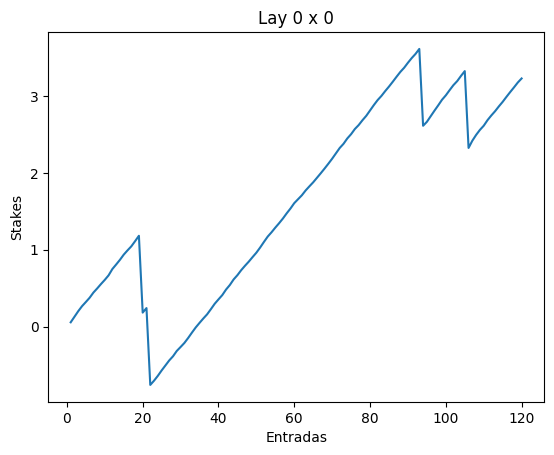

In [8]:
# Responsabilidade Fixa e Lucro Variável
green = (Stake * 0.944) / (df0['Odd_0x0'] - 1)
red = -Stake

df0['Profit'] = np.where((df0['Lay_0x0'] == 1), green, red)
df0['Investimento'] = Stake

plot_profit_acu(df0, "Lay 0 x 0")

Metodo: Lay 0 x 0
Profit: 54.0 stakes em 120 jogos
ROI: 2.94 %
Drawdown Maximo Acumulado: -27.06
Winrate Medio: 96.67 %
Desvio Padrao: 2.68



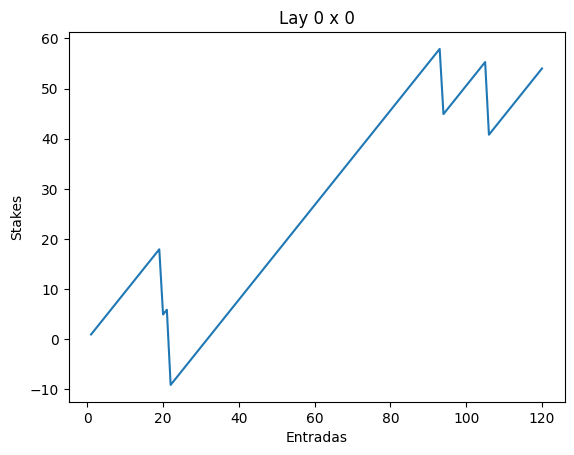

In [9]:
# Lucro Fixo e Responsabilidade Variável
green = (Stake * 0.944)
red = Stake * (1 - df0['Odd_0x0'])

df0['Profit'] = np.where((df0['Lay_0x0'] == 1), green, red)
df0['Investimento'] = df0['Odd_0x0'] - 1

plot_profit_acu(df0, "Lay 0 x 0")

### Teste

In [10]:
df_test['p_Under'] = 1 / df_test['Odd_Under25']
df_test['p_0x0'] = 1 / df_test['Odd_0x0']

df_test['VAR'] = df_test['p_0x0'] / df_test['p_Under']

flt = (df_test.VAR > 0.121) & (df_test.VAR <= 0.124) & (df_test['Odd_0x0'] > 1) & (df_test['Odd_0x0'] <= 21)
df0 = df_test[flt]
df0 = drop_reset_index(df0)

Metodo: Lay 0 x 0
Profit: 4.74 stakes em 113 jogos
ROI: 4.2 %
Drawdown Maximo Acumulado: -1.32
Winrate Medio: 98.23 %
Desvio Padrao: 0.14



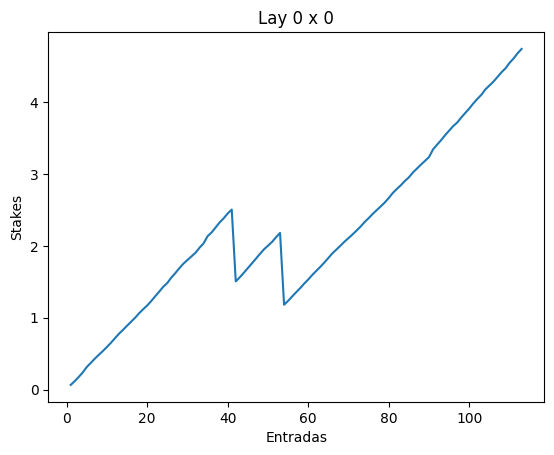

In [11]:
# Responsabilidade Fixa e Lucro Variável
green = (Stake * 0.944) / (df0['Odd_0x0'] - 1)
red = -Stake

df0['Profit'] = np.where((df0['Lay_0x0'] == 1), green, red)
df0['Investimento'] = Stake

plot_profit_acu(df0, "Lay 0 x 0")

Metodo: Lay 0 x 0
Profit: 75.78 stakes em 113 jogos
ROI: 4.25 %
Drawdown Maximo Acumulado: -18.62
Winrate Medio: 98.23 %
Desvio Padrao: 2.06



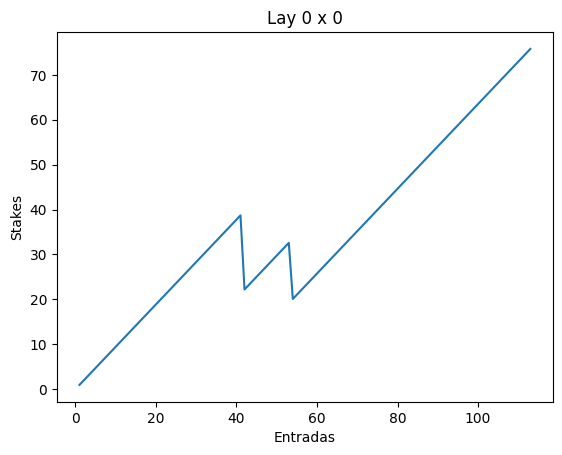

In [12]:
# Lucro Fixo e Responsabilidade Variável
green = (Stake * 0.944)
red = Stake * (1 - df0['Odd_0x0'])

df0['Profit'] = np.where((df0['Lay_0x0'] == 1), green, red)
df0['Investimento'] = df0['Odd_0x0'] - 1

plot_profit_acu(df0, "Lay 0 x 0")

### Backtesting Full

In [13]:
df['p_Under'] = 1 / df['Odd_Under25']
df['p_0x0'] = 1 / df['Odd_0x0']

df['VAR'] = df['p_0x0'] / df['p_Under']

flt = (df.VAR > 0.121) & (df.VAR <= 0.124) & (df['Odd_0x0'] > 1) & (df['Odd_0x0'] <= 21)
df0 = df[flt]
df0 = drop_reset_index(df0)

Metodo: Lay 0 x 0
Profit: 7.97 stakes em 233 jogos
ROI: 3.42 %
Drawdown Maximo Acumulado: -1.94
Winrate Medio: 97.42 %
Desvio Padrao: 0.17



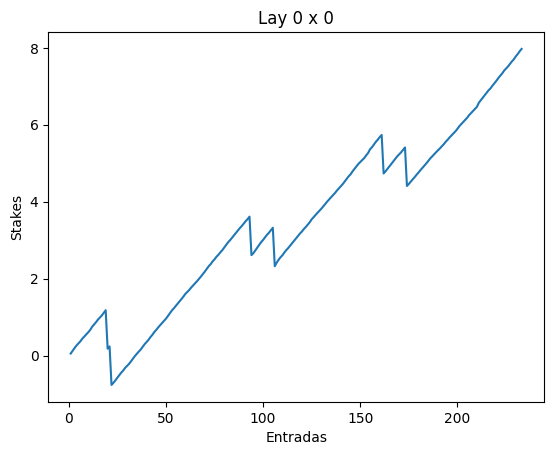

In [14]:
# Responsabilidade Fixa e Lucro Variável
green = (Stake * 0.944) / (df0['Odd_0x0'] - 1)
red = -Stake

df0['Profit'] = np.where((df0['Lay_0x0'] == 1), green, red)
df0['Investimento'] = Stake

plot_profit_acu(df0, "Lay 0 x 0")

Metodo: Lay 0 x 0
Profit: 129.79 stakes em 233 jogos
ROI: 3.59 %
Drawdown Maximo Acumulado: -27.06
Winrate Medio: 97.42 %
Desvio Padrao: 2.4



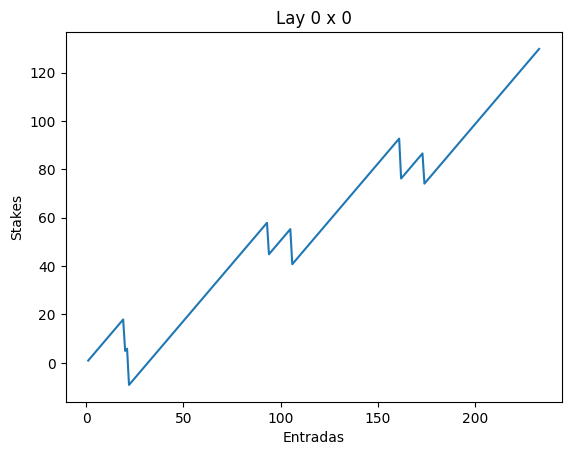

In [15]:
# Lucro Fixo e Responsabilidade Variável
green = (Stake * 0.944)
red = Stake * (1 - df0['Odd_0x0'])

df0['Profit'] = np.where((df0['Lay_0x0'] == 1), green, red)
df0['Investimento'] = df0['Odd_0x0'] - 1

plot_profit_acu(df0, "Lay 0 x 0")

### Risco de Ruina

In [17]:
# Lucro Fixo e Resonsabilidade Variável
Por = 1

df0['Profit2'] = Por *  df0['Profit']

import statistics

blocos = np.array_split(df0, 10)
df1, df2, df3, df4, df5, df6, df7, df8, df9, df10 = blocos

media1 = df1['Profit2'].mean()
media2 = df2['Profit2'].mean()
media3 = df3['Profit2'].mean()
media4 = df4['Profit2'].mean()
media5 = df5['Profit2'].mean()
media6 = df6['Profit2'].mean()
media7 = df7['Profit2'].mean()
media8 = df8['Profit2'].mean()
media9 = df9['Profit2'].mean()
media10 = df10['Profit2'].mean()

lista_medias = [media1, media2, media3, media4, media5, media6, media7, media8, media9, media10]

media = statistics.mean(lista_medias)
desvio_padrao = statistics.stdev(lista_medias)

banca = 1.00

risco_de_ruina = (np.exp((-2 * media * banca) / (desvio_padrao ** 2))) * 100
print(f"O Risco de Ruina dessa Estratégia é {round(risco_de_ruina,2)}%")

O Risco de Ruina dessa Estratégia é 0.37%


### Jogos do Dia

In [18]:
dia = '2024-06-08'

df = pd.read_csv(f'https://github.com/futpythontrader/YouTube/raw/main/Jogos_do_Dia/Betfair/Jogos_do_Dia_Betfair_Back_Lay_{dia}.csv')

df = df[['Date','Time','League','Home','Away','IDMercado_Correct_Score',
'Odd_H_Back','Odd_A_Back','Odd_D_Back','Odd_Under25_FT_Back','Odd_Over25_FT_Back','Odd_BTTS_Yes_Back','Odd_BTTS_No_Back',
'Odd_CS_0x0_Lay','Odd_CS_0x1_Lay','Odd_CS_1x0_Lay']]
df.columns = ['Date','Time','League','Home','Away','IDMercado_Correct_Score',
'Odd_H','Odd_A','Odd_D','Odd_Under25','Odd_Over25','Odd_BTTS_Yes','Odd_BTTS_No',
'Odd_CS_0x0_Lay','Odd_CS_0x1_Lay','Odd_CS_1x0_Lay']

rename_leagues(df['League'])

df = df[df['League'].isin(leagues) == True]

df['p_Under'] = 1 / df['Odd_Under25']
df['p_0x0'] = 1 / df['Odd_CS_0x0_Lay']

df['VAR'] = df['p_0x0'] / df['p_Under']

flt = (df.VAR > 0.121) & (df.VAR <= 0.124) & (df['Odd_CS_0x0_Lay'] > 1) & (df['Odd_CS_0x0_Lay'] <= 21)
df0 = df[flt]
df0 = drop_reset_index(df0)
df0


,Date,Time,League,Home,Away,IDMercado_Correct_Score,Odd_H,Odd_A,Odd_D,Odd_Under25,Odd_Over25,Odd_BTTS_Yes,Odd_BTTS_No,Odd_CS_0x0_Lay,Odd_CS_0x1_Lay,Odd_CS_1x0_Lay,p_Under,p_0x0,VAR
1,2024-06-08,11:00:00,FINLAND - VEIKKAUSLIIGA,KuPS,AC Oulu,1.229571,1.55,6.8,4.6,2.18,1.79,1.92,2.0,18.0,25.0,9.0,0.458716,0.055556,0.121111
